# Term enrichment of the DFA Superdataset with OAK
This notebook tests whether positive answers to particular kinds of OHD questions are over-represented in a subset of records (the **sample**, or test set) compared with a larger set of records (the **background**). It uses the [OAK class enrichment](https://incatools.github.io/ontology-access-kit/guide/enrichment.html) functionality with the [Oral Health and Disease Ontology (OHD)](http://purl.obolibrary.org/obo/ohd.owl).

**How the pieces fit together**
* **Subjects** are superdataset records (participants).
* **Associations** link a record to an OHD question class when the participant gave a *positive* answer to that question, e.g., `record --> OHD:0000421 (DFS 01)` if they answered 4 (*Often*) or 5 (*Nearly every time*). The links come from the punned data properties (e.g., `sd:dfs1 rdfs:subClassOf OHD:0000421`).
* **Roll-up**: OAK counts a record under every ancestor of its associated classes (via `rdfs:subClassOf`), so we can find enrichment at higher levels, e.g., *dental visit avoidance question*.
* **Test**: for each OHD class, a one-sided hypergeometric test compares the number of sample records associated with the class against the background, with a Bonferroni correction (`p_value_adjusted`).

**Workflow**
1. Build a SQLite version of OHD (semantic-sql), once.
2. Use SPARQL over the superdataset graph `g` to create the associations.
3. Load the associations into a copy of the OHD database (`term_association` table).
4. Use SPARQL to define a sample and background set of records.
5. Run the enrichment.
6. Visualize the results.

**Why SPARQL (not SQL) for the test set:** the record-level data (answers, demographics, study) is in the RDF graph; the SQLite database only holds OHD plus the associations. So it is easiest to select records with SPARQL. The sample and background are just lists of record IDs (one ID per line if saved to a file); they must use the same IDs as the associations.

**Things to know**
* Records are blank nodes, so the record IDs (`sdrec:<blank node id>`) only stay the same within one load of `g`. Re-run the association, sample and background cells together after reloading `g`.
* oaklib 0.7.4 has two problems that this workflow works around:
  * The in-memory association store ignores the subject list when it has 200+ entries, which gives wrong counts (and a `math domain error`). This also affects `runoak ... -g associations.tsv enrichment`. Storing the associations in the SQLite database and setting `adapter.can_store_associations = True` avoids it.
  * `adapter.add_associations()` fails on the semsql `term_association` table (missing `id`), so the associations are inserted with `sqlite3`.
* Instruments differ by study (e.g., MDAS is only in `sohea` and `mdas`). Compare records that were asked the same instrument, otherwise enrichment mostly reflects which questionnaire a study used.

**Requirements**
* `DFA-data/superdataset-data.ttl`: run `make superdataset-data.ttl` from the root directory to build.
* python packages: `oaklib`, `linkml`, `rdflib`, `SPARQLWrapper`, `pandas`, `matplotlib`
* [semantic-sql](https://github.com/INCATools/semantic-sql) (`semsql`) with `robot`, `rdftab` and `relation-graph` on the `PATH` (to build the OHD database)
* [obographviz](https://github.com/INCATools/obographviz) (`og2dot`) and Graphviz (`dot`) (to draw the results)

In [1]:
import shutil
import sqlite3
import subprocess
import textwrap
import urllib.request
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from linkml_runtime import SchemaView
from oaklib import get_adapter
from oaklib.datamodels.vocabulary import IS_A
from oaklib.utilities.obograph_utils import graph_to_image
from rdflib import BNode, Graph, Literal, URIRef
from scipy.stats import fisher_exact
from SPARQLWrapper import JSON, SPARQLWrapper

/opt/homebrew/lib/python3.11/site-packages/eutils/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## helper functions

In [2]:
def sparql_df(query, source="http://127.0.0.1:8000/", to_python=True):
    """Run a SPARQL SELECT query and return the results as a pandas DataFrame.

    Args:
        query: SPARQL SELECT query.
        source: an rdflib Graph, or the URL of a SPARQL endpoint.
        to_python: convert literals to Python values (e.g., xsd:integer -> int);
            if False, every value is returned as a string.
    """
    def convert(term):
        if term is None:
            return None
        if to_python and isinstance(term, Literal):
            value = term.toPython()
            return float(value) if isinstance(value, Decimal) else value
        return str(term)

    def to_term(b):
        # JSON result binding -> rdflib term
        if b is None:
            return None
        if b["type"] == "uri":
            return URIRef(b["value"])
        if b["type"] == "bnode":
            return BNode(b["value"])
        return Literal(b["value"], lang=b.get("xml:lang"), datatype=b.get("datatype"))

    if isinstance(source, Graph):
        res = source.query(query)
        cols = [str(v) for v in res.vars]
        rows = [[convert(term) for term in row] for row in res]
    else:
        sw = SPARQLWrapper(source)
        sw.setQuery(query)
        sw.setReturnFormat(JSON)
        res = sw.query().convert()
        cols = res["head"]["vars"]
        rows = [[convert(to_term(b.get(c))) for c in cols] for b in res["results"]["bindings"]]

    df = pd.DataFrame(rows, columns=cols)
    # use nullable types so integer columns with missing values stay integers
    return df.convert_dtypes() if to_python else df

In [3]:
def run_enrichment(adapter, sample, background, cutoff=0.05, filter_redundant=False):
    """Run OAK class enrichment on OHD and return the results as a DataFrame.

    Args:
        adapter: OAK sqlite adapter for the OHD database with the associations.
        sample: list of record IDs to test (the test set).
        background: list of record IDs to compare against.
        cutoff: maximum adjusted p-value to report.
        filter_redundant: drop classes that are ancestors/descendants of a more
            significant result (otherwise they are flagged).
    """
    results = adapter.enriched_classes(
        subjects=sample,
        background=background,
        object_closure_predicates=[IS_A],
        cutoff=cutoff,
        autolabel=True,
        filter_redundant=filter_redundant,
    )
    cols = ["rank", "class_id", "class_label", "sample_count", "sample_total",
            "background_count", "background_total", "p_value", "p_value_adjusted",
            "ancestor_of_more_informative_result", "descendant_of_more_informative_result"]
    df = pd.DataFrame([{c: getattr(r, c) for c in cols} for r in results], columns=cols)
    df["sample_pct"] = (100 * df.sample_count / df.sample_total).round(1)
    df["background_pct"] = (100 * df.background_count / df.background_total).round(1)
    return df

In [4]:
def plot_enrichment(adapter, enrichment, imgfile, top_class="OHD:0008011", width=30):
    """Draw the enriched OHD classes and their ancestors with OAK's viz (og2dot).

    Enriched classes are highlighted (thick border) and labelled with the
    percentage of sample vs background records and the adjusted p-value.
    Ancestors above `top_class` (default: 'question') are left out.

    Args:
        adapter: OAK sqlite adapter for the OHD database.
        enrichment: DataFrame returned by run_enrichment.
        imgfile: path of the PNG file to write.
        top_class: highest ancestor to show.
        width: maximum number of characters per label line.
    """
    ids = enrichment["class_id"].tolist()
    graph = adapter.ancestor_graph(ids, predicates=[IS_A])

    # drop the upper-level ancestors (BFO, IAO, ...) and the predicate node OAK adds
    keep = set(adapter.descendants(top_class, predicates=[IS_A]))
    graph.nodes = [n for n in graph.nodes if n.id in keep]
    graph.edges = [e for e in graph.edges if e.sub in keep and e.obj in keep]

    # og2dot puts every word on its own line; wrap the labels ourselves and use
    # non-breaking spaces within a line, then add the stats for enriched classes
    stats = enrichment.set_index("class_id")
    for node in graph.nodes:
        lines = textwrap.wrap(node.lbl or node.id, width)
        if node.id in stats.index:
            r = stats.loc[node.id]
            lines += [f"{r.sample_pct:.1f}% vs {r.background_pct:.1f}%",
                      f"adj. p = {r.p_value_adjusted:.1e}"]
        node.lbl = "\n".join(line.replace(" ", " ") for line in lines)

    graph_to_image(
        graph,
        seeds=ids,                                      # highlight the enriched classes
        configure='{"relationProperties": {"rdfs:subClassOf": {"label": ""}}}',
        imgfile=str(imgfile),
    )
    display(Image(filename=str(imgfile)))

In [5]:
def show_image(path, scale=1.0, dpi=100):
    """Display an image file with matplotlib at (roughly) its actual pixel size."""
    img = plt.imread(path)
    height, width = img.shape[:2]
    fig = plt.figure(figsize=(scale * width / dpi, scale * height / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])   # image fills the figure (no margins)
    ax.imshow(img)
    ax.axis("off")
    plt.show()

## settings
All generated files go in `DFA-data/enrichment/`, which is gitignored because it contains participant-derived data.

In [6]:
DATA_TTL = Path("DFA-data/superdataset-data.ttl")      # superdataset records + schema + puns
ENRICH_DIR = Path("DFA-data/enrichment")              # gitignored (contains participant data)
OHD_OWL = Path("../../ohd-ontology/ohd.owl")          # local OHD release (optional, see step 1)
OHD_DB = ENRICH_DIR / "ohd.db"                        # OHD as semantic-sql database
OHD_DFA_DB = ENRICH_DIR / "ohd-dfa.db"                # OHD + superdataset associations
SCHEMA = "../src/schema/superdataset.yaml"

ENRICH_DIR.mkdir(parents=True, exist_ok=True)

## load the superdataset graph
`superdataset-data.ttl` merges the records, the punned data properties and the OWL version of the schema (run `make superdataset-data.ttl` from the root directory to build it).

In [7]:
g = Graph().parse(DATA_TTL)
print(f"{len(g):,} triples")

651,451 triples


### 1. Build the OHD SQLite database
Uses [semantic-sql](https://github.com/INCATools/semantic-sql) (`semsql`), which needs `robot`, `rdftab` and `relation-graph` on the `PATH`.

`OHD_SOURCE` sets where `ohd.owl` comes from:
* `"auto"` (default): the local [ohd-ontology](https://github.com/oral-health-and-disease-ontologies/ohd-ontology) repo (`OHD_OWL`) if it exists, otherwise download it
* `"local"`: the local ohd-ontology repo
* `"purl"`: download the latest release from the OBO Foundry PURL (http://purl.obolibrary.org/obo/ohd.owl); use this if you don't have the ohd-ontology repo

`ohd.db` is only built if it doesn't exist. Set `REBUILD_OHD_DB = True` (or delete `ohd.db`) to rebuild it, e.g., when OHD has changed or after changing `OHD_SOURCE`.

In [8]:
# Where to get ohd.owl:
#   "auto"  - use the local ohd-ontology repo (OHD_OWL) if it exists, otherwise download
#   "local" - use the local ohd-ontology repo (OHD_OWL)
#   "purl"  - download the latest release from the OBO Foundry PURL
OHD_SOURCE = "auto"
OHD_PURL = "http://purl.obolibrary.org/obo/ohd.owl"
REBUILD_OHD_DB = False   # set to True to rebuild ohd.db (e.g., after changing OHD_SOURCE)

if REBUILD_OHD_DB or not OHD_DB.exists():
    if OHD_SOURCE not in ("auto", "local", "purl"):
        raise ValueError(f"OHD_SOURCE must be 'auto', 'local' or 'purl', not {OHD_SOURCE!r}")
    if OHD_SOURCE == "local" or (OHD_SOURCE == "auto" and OHD_OWL.exists()):
        print(f"using local {OHD_OWL}")
        shutil.copy(OHD_OWL, ENRICH_DIR / "ohd.owl")
    else:
        print(f"downloading {OHD_PURL}")
        urllib.request.urlretrieve(OHD_PURL, ENRICH_DIR / "ohd.owl")
    OHD_DB.unlink(missing_ok=True)
    build = subprocess.run(["semsql", "make", "ohd.db"], cwd=ENRICH_DIR, capture_output=True, text=True)
    if build.returncode != 0:
        raise RuntimeError(f"semsql failed:\n{build.stderr[-3000:]}")
print(OHD_DB, f"{OHD_DB.stat().st_size / 1e6:.1f} MB")

DFA-data/enrichment/ohd.db 20.1 MB


### 2. Create the associations (record → OHD question class)
A **positive** answer is defined from the response scales in the LinkML schema:
* 1–5 scales (DFS, IDAF-4C+ 1 and 3, MDAS): 4 or 5 (*Often / Much / Agree / Very anxious* or higher)
* yes/no items (IDAF-4C+ 2, `NoYesMissing`): 1 (*Yes*)

Missing (`-9999`) and not asked (`-9876`) codes are never positive.

In [9]:
# minimum value that counts as a positive answer, for each punned question slot
sv = SchemaView(SCHEMA)
positive_min = {}
for name in sv.class_slots("Record"):
    slot = sv.induced_slot(name, "Record")
    if "pun_as" in (slot.annotations or {}):
        positive_min[name] = 1 if slot.range == "NoYesMissing" else 4

values = " ".join(f"(sd:{name} {n})" for name, n in positive_min.items())
q_assoc = f"""
PREFIX sd: <https://w3id.org/OHD/DFA-study/superdataset/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?record ?ohd_class
WHERE {{
  VALUES (?item ?min_positive) {{ {values} }}
  ?item rdfs:subClassOf ?ohd_class .             # punned slot -> OHD question
  FILTER(STRSTARTS(STR(?ohd_class), "http://purl.obolibrary.org/obo/OHD_"))
  ?record ?item ?value .
  FILTER(?value >= ?min_positive)
}}
"""
assoc = sparql_df(q_assoc, g)
assoc["subject"] = "sdrec:" + assoc["record"]
assoc["object"] = assoc["ohd_class"].str.replace("http://purl.obolibrary.org/obo/OHD_", "OHD:")
assoc = assoc[["subject", "object"]].drop_duplicates()
print(f"{len(positive_min)} questions, {len(assoc):,} associations, {assoc.subject.nunique():,} records")
assoc.object.value_counts().head()

48 questions, 22,877 associations, 4,468 records


object
OHD:0000448    1562
OHD:0000436    1498
OHD:0000450    1392
OHD:0000438    1295
OHD:0000435    1276
Name: count, dtype: Int64

### 3. Load the associations into a copy of the OHD database
The associations go into the `term_association` table. The copy is rebuilt each time so it always matches the current `g`.

In [10]:
shutil.copy(OHD_DB, OHD_DFA_DB)
rows = assoc.assign(
    id=assoc.subject + "|" + assoc.object,
    predicate="OHD:has_positive_response",          # label for the association type
    source="infores:dfa-superdataset",
)
with sqlite3.connect(OHD_DFA_DB) as con:
    con.execute("DELETE FROM term_association")
    rows[["id", "subject", "predicate", "object", "source"]].to_sql(
        "term_association", con, if_exists="append", index=False)
    con.execute("CREATE INDEX IF NOT EXISTS ta_subject ON term_association(subject)")
    con.execute("CREATE INDEX IF NOT EXISTS ta_object ON term_association(object)")
    print("term_association rows:", con.execute("SELECT COUNT(*) FROM term_association").fetchone()[0])

adapter = get_adapter(f"sqlite:{OHD_DFA_DB}")
adapter.can_store_associations = True   # use the SQL association queries (see note above)

term_association rows: 22877


### 4. Define the sample and background
Example question: *Among participants who answered the DFS, which kinds of fear questions are more often answered positively by people whose last dental visit was 5 or more years ago (or never)?*
* **background**: records with a DFS answer (`dfs1 >= 1`) and a known `Last_Dental_Visit`
* **sample**: background records with `Last_Dental_Visit` 4 (*5 or more years*) or 5 (*never*)

Any SPARQL query that returns `?record` can be used to define other test sets.

In [11]:
q_records = """
PREFIX sd: <https://w3id.org/OHD/DFA-study/superdataset/>
SELECT ?record ?last_visit
WHERE {
  ?record sd:dfs1 ?dfs1 ;
          sd:Last_Dental_Visit ?last_visit .
  FILTER(?dfs1 >= 1)          # answered the DFS
  FILTER(?last_visit >= 1)    # last visit known
}
"""
recs = sparql_df(q_records, g)
recs["subject"] = "sdrec:" + recs["record"]

background = recs["subject"].tolist()
sample = recs.loc[recs.last_visit.isin([4, 5]), "subject"].tolist()
print(f"background: {len(background):,} records | sample: {len(sample):,} records")

background: 4,290 records | sample: 498 records


### 5. Run the enrichment
`run_enrichment` (see helper functions) returns a DataFrame. Useful options:
* `cutoff`: maximum adjusted p-value to report.
* `filter_redundant=True`: drop classes that are ancestors/descendants of a more significant result (shown as flags otherwise).

In [12]:
enrichment = run_enrichment(adapter, sample, background)
enrichment[["class_id", "class_label", "sample_count", "sample_pct", "background_count",
            "background_pct", "p_value", "p_value_adjusted"]]

,class_id,class_label,sample_count,sample_pct,background_count,background_pct,p_value,p_value_adjusted
0,OHD:0000421,DFS 01. Has fear of dental work ever caused yo...,110,22.1,565,13.2,3.159707e-09,2.180198e-07
1,OHD:0008024,question about delay in scheduling a dental ap...,124,24.9,688,16.0,3.568982e-08,2.462598e-06
2,OHD:0008022,dental visit avoidance question,136,27.3,785,18.3,8.207534e-08,5.663198e-06
3,OHD:0008021,health encounter avoidance question,136,27.3,785,18.3,8.207534e-08,5.663198e-06
4,OHD:0008020,avoidance behavior question,136,27.3,785,18.3,8.207534e-08,5.663198e-06
5,OHD:0000422,DFS 02. Has fear of dental work ever caused yo...,55,11.0,267,6.2,8.712269e-06,6.011466e-04
6,OHD:0008023,question about canceling or not showing up for...,55,11.0,267,6.2,8.712269e-06,6.011466e-04
7,OHD:0000429,DFS 08. Making an appointment for dentistry.,49,9.8,234,5.5,1.758919e-05,1.213654e-03
8,OHD:0000430,DFS 09. Approaching the dentist’s office.,55,11.0,295,6.9,1.643350e-04,1.133912e-02
9,OHD:0000441,"DFS 20. All things considered, how fearful are...",104,20.9,656,15.3,2.325163e-04,1.604363e-02


In [13]:
# only the most informative (non-redundant) classes
run_enrichment(adapter, sample, background, filter_redundant=True)[
    ["class_id", "class_label", "sample_pct", "background_pct", "p_value_adjusted"]]

,class_id,class_label,sample_pct,background_pct,p_value_adjusted
0,OHD:0000421,DFS 01. Has fear of dental work ever caused yo...,22.1,13.2,2.180198e-07
1,OHD:0000429,DFS 08. Making an appointment for dentistry.,9.8,5.5,1.213654e-03
2,OHD:0000430,DFS 09. Approaching the dentist’s office.,11.0,6.9,1.133912e-02
3,OHD:0000441,"DFS 20. All things considered, how fearful are...",20.9,15.3,1.604363e-02
4,OHD:0000432,DFS 11. Being seated in the dental chair.,16.9,12.0,3.038114e-02


### Interpreting the results
The numbers in this section come from `merged_dfa_data_cleaned_2026_09_30.csv`: 4,290 DFS respondents with a known last dental visit (background), of whom 498 last saw a dentist 5 or more years ago or never (sample). The cells below recompute the supporting checks; re-read the text if the data or the sample definition changes.

**Fear-driven avoidance separates the two groups.** DFS 01 (*Has fear of dental work ever caused you to put off making an appointment?*) is the strongest result: 22.1% of the sample answered *Often* or *Nearly every time*, against 13.2% of the background (adjusted p = 2.2e-07). DFS 02 (fear caused you to cancel or not show up) follows the same pattern, 11.0% vs 6.2% (adjusted p = 6.0e-04). OHD groups both items under *dental visit avoidance question*, and that class rolls up through *health encounter avoidance question* to *avoidance behavior question*, each at 27.3% vs 18.3%. The roll-up is where the ontology adds something a per-item analysis would not: it shows the signal belongs to one branch of OHD, not to scattered items.

The anticipatory items point the same way. Fear of *making an appointment* (DFS 08, 9.8% vs 5.5%) and of *approaching the dentist's office* (DFS 09, 11.0% vs 6.9%) are enriched, along with the global rating in DFS 20 (*how fearful are you of having dental work done?*, 20.9% vs 15.3%) and fear of *being seated in the dental chair* (DFS 11, 16.9% vs 12.0%). With `filter_redundant=True`, OAK reduces the list to these five items: DFS 01, 08, 09, 11 and 20.

**What is not enriched matters as much.** None of the physiological-arousal items (DFS 03–07: tense muscles, faster breathing, perspiring, nausea, faster heartbeat) survive correction; DFS 03 is endorsed by 15.9% of both groups. Most fears of specific stimuli, such as the drill (DFS 16–18) and the needle (DFS 14–15), also fall short. And the share of records with at least one positive answer of any kind barely differs (*question*: 56.2% vs 50.3%, adjusted p = 0.20). People who stay away from the dentist are not uniformly more fearful. Their excess fear sits in avoiding and anticipating the visit, not in reactions to what happens in the chair.

**Part of the avoidance result is built into the design.** DFS 01 and DFS 02 ask whether fear has led someone to delay or cancel appointments, and the sample was selected for not having seen a dentist in 5 or more years. A positive association between the two is expected, so it works mainly as a consistency check: the respondents' behavior lines up with the way OHD classifies the questions. The pattern of non-enrichment above is the less obvious finding.

#### Supporting checks
All tested classes, including those that were not significant (`cutoff=1.0` reports every hypothesis):

In [ ]:
all_results = run_enrichment(adapter, sample, background, cutoff=1.0)
print(f"{len(all_results)} classes tested")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 80):
    display(all_results[["class_id", "class_label", "sample_pct", "background_pct",
                         "p_value", "p_value_adjusted"]])

Study mix and a per-study check of DFS 01. OAK's test pools all studies, so it cannot tell a real difference from a difference in which studies the sample comes from. The Mantel–Haenszel odds ratio combines the per-study 2×2 tables (sample vs rest, DFS 01 positive vs not); compare it with the crude (pooled) odds ratio.

In [ ]:
q_people = """
PREFIX sd: <https://w3id.org/OHD/DFA-study/superdataset/>
SELECT ?record ?source ?age ?sex
WHERE {
  ?record sd:source ?source .
  OPTIONAL { ?record sd:Age ?age }
  OPTIONAL { ?record sd:Sex ?sex }
}
"""
people = recs.merge(sparql_df(q_people, g), on="record")
people["in_sample"] = people["subject"].isin(set(sample))
people["dfs01_positive"] = people["subject"].isin(set(assoc.loc[assoc.object == "OHD:0000421", "subject"]))

# study mix
study_mix = pd.DataFrame({
    "sample_%": people[people.in_sample].source.value_counts(normalize=True).mul(100).round(1),
    "background_%": people.source.value_counts(normalize=True).mul(100).round(1),
    "background_n": people.source.value_counts(),
})
display(study_mix)

# DFS 01 within each study: sample vs the rest of the background
rows = []
mh_num = mh_den = 0
for source, x in people.groupby("source"):
    a = (x.in_sample & x.dfs01_positive).sum()      # sample, positive
    b = (x.in_sample & ~x.dfs01_positive).sum()     # sample, not positive
    c = (~x.in_sample & x.dfs01_positive).sum()     # rest, positive
    d = (~x.in_sample & ~x.dfs01_positive).sum()    # rest, not positive
    rows.append({"source": source, "sample_n": a + b, "sample_%": round(100 * a / (a + b), 1),
                 "rest_n": c + d, "rest_%": round(100 * c / (c + d), 1),
                 "fisher_p": fisher_exact([[a, b], [c, d]])[1]})
    mh_num += a * d / len(x)
    mh_den += b * c / len(x)
display(pd.DataFrame(rows))

a = (people.in_sample & people.dfs01_positive).sum(); b = (people.in_sample & ~people.dfs01_positive).sum()
c = (~people.in_sample & people.dfs01_positive).sum(); d = (~people.in_sample & ~people.dfs01_positive).sum()
print(f"DFS 01 odds ratio, crude: {a * d / (b * c):.2f} | stratified by study (Mantel-Haenszel): {mh_num / mh_den:.2f}")

Age and sex of the sample and background, and DFS 01 / DFS 20 by sex in the background (1 = male, 2 = female):

In [ ]:
valid_age = people.age >= 0
print(f"mean age: sample {people[people.in_sample & valid_age].age.mean():.1f} | "
      f"background {people[valid_age].age.mean():.1f}")
print(f"female: sample {100 * (people[people.in_sample].sex == 2).mean():.1f}% | "
      f"background {100 * (people.sex == 2).mean():.1f}%")

people["dfs20_positive"] = people["subject"].isin(set(assoc.loc[assoc.object == "OHD:0000441", "subject"]))
(people[people.sex.isin([1, 2])]
 .groupby("sex")[["dfs01_positive", "dfs20_positive"]].mean().mul(100).round(1))

#### Caveats
* **Study mix.** The sample over-represents cohra1 (47.6% vs 36.6% of the background) and randall (23.3% vs 14.3%), and randall respondents endorse DFS 01 more often regardless of attendance (26.6% among those seen in the last 5 years). Stratifying by study lowers the DFS 01 odds ratio from 2.08 to 1.84. The sample percentage is higher than the rest of its study in all six studies, but the difference is individually significant only in cohra1, the largest study (18.1% vs 8.2%, Fisher p < 0.0001). Study accounts for part of the pooled result, not all of it.
* **Age and sex.** The sample is older (mean 36.7 vs 33.5 years) and has fewer women (58.0% vs 72.8%). DFS 01 endorsement does not differ by sex in these data (13.4% of men, 13.0% of women), so the sex imbalance does not explain it. Women endorse DFS 20 more often (16.1% vs 13.3%), so the shortage of women in the sample works against the DFS 20 result. The OAK test adjusts for none of these variables; a logistic regression with study, age and sex as covariates is the next step for any item we want to report.
* **IDAF-4C+ results cannot be read from this run.** Only bph, f31 and tic gave both the DFS and the IDAF-4C+ (13.9% of the sample, 17.1% of the background). OAK divides by all records, so IDAF-4C+ percentages are diluted by people who were never asked. To test IDAF-4C+ items, restrict the sample and background to IDAF-4C+ respondents.
* **Definition of a positive answer.** Positive means 4 or 5 on the 1–5 scales. A cut at 3 or above, or the full score, could change which items reach significance.
* **Multiple testing.** The adjustment is Bonferroni over 69 classes. Because classes are nested (every item is counted again in its ancestors), the tests are strongly correlated and Bonferroni is conservative. Items just above the cutoff, such as DFS 16 (*seeing the drill*, adjusted p = 0.16) and DFS 19 (*having your teeth cleaned*, adjusted p = 0.22), should not be read as evidence of no difference.
* **OHD modelling.** OHD asserts *avoidance or anticipatory fear question* (OHD:0008007) as a subclass of *Dental Fear Survey (DFS) question* (OHD:0008010), so four IDAF-4C+ items are counted as DFS questions. This affects the *DFS question* row (54.0% vs 47.9%, not significant), not the item-level results.
* **Cross-sectional data.** The analysis shows co-occurrence. It cannot show whether fear leads to staying away, staying away lets fear grow, or both.

### Optional: save the inputs as files
The files use the formats OAK expects: the sample and background are one record ID per line; the associations are a two-column TSV (`subject<TAB>object`, the `g2t` format). They are only valid for the current load of `g` (blank node IDs).

The equivalent command line (`runoak -i sqlite:ohd.db -G g2t -g associations.tsv enrichment -p i -U sample.txt -B background.txt`) currently gives wrong results because of the oaklib issue described above, so use the Python workflow.

In [14]:
(ENRICH_DIR / "sample.txt").write_text("\n".join(sample) + "\n")
(ENRICH_DIR / "background.txt").write_text("\n".join(background) + "\n")
assoc.to_csv(ENRICH_DIR / "associations.tsv", sep="\t", index=False, header=False)
enrichment.to_csv(ENRICH_DIR / "enrichment-dfs-last-visit-5plus-years.tsv", sep="\t", index=False)
sorted(p.name for p in ENRICH_DIR.iterdir())

['associations.tsv',
 'background.txt',
 'enrichment-dfs-last-visit-5plus-years.png',
 'enrichment-dfs-last-visit-5plus-years.tsv',
 'ohd-dfa.db',
 'ohd-relation-graph.tsv.gz',
 'ohd.db',
 'ohd.owl',
 'sample.txt']

### 6. Visualize the results
`plot_enrichment` (see helper functions) uses OAK's built-in graph visualization (`graph_to_image`, the same as `runoak viz`), which needs [obographviz](https://github.com/INCATools/obographviz) (`og2dot`) and Graphviz (`dot`).
* The graph shows the enriched classes and their ancestors up to *question*; arrows point from a class to its parent (`rdfs:subClassOf`).
* Enriched classes have a thick border and show **% of sample records vs % of background records** with a positive answer, and the adjusted p-value.
* The image is also saved to `DFA-data/enrichment/`.

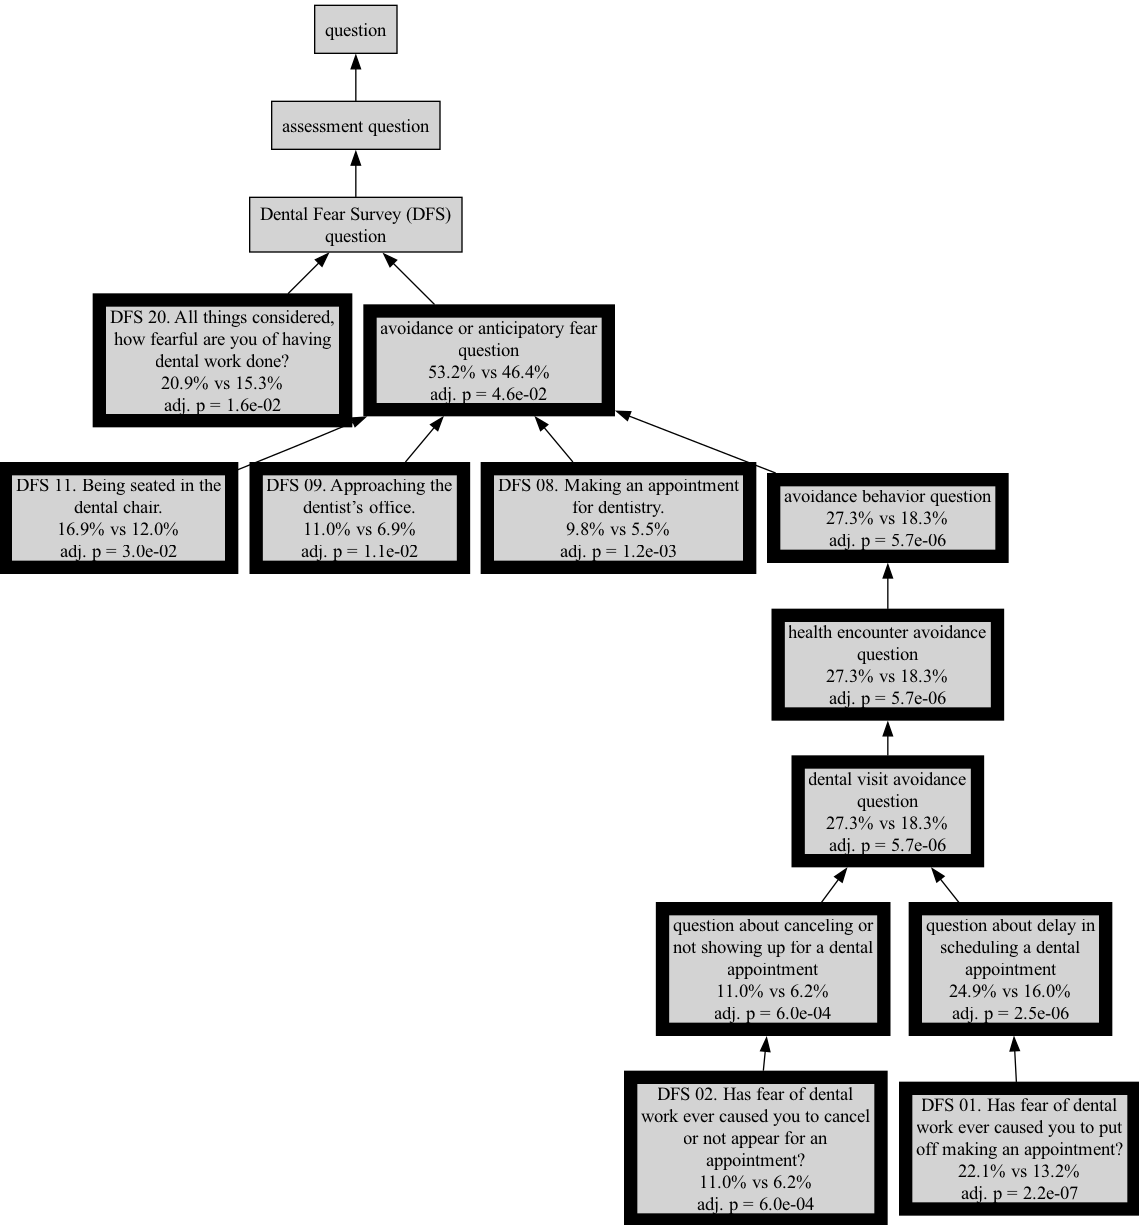

In [15]:
plot_enrichment(adapter, enrichment, ENRICH_DIR / "enrichment-dfs-last-visit-5plus-years.png")

### Display a saved enrichment image
`show_image` (see helper functions) shows a PNG saved by `plot_enrichment` with matplotlib, without re-running the enrichment. Increase `scale` to make the image larger.

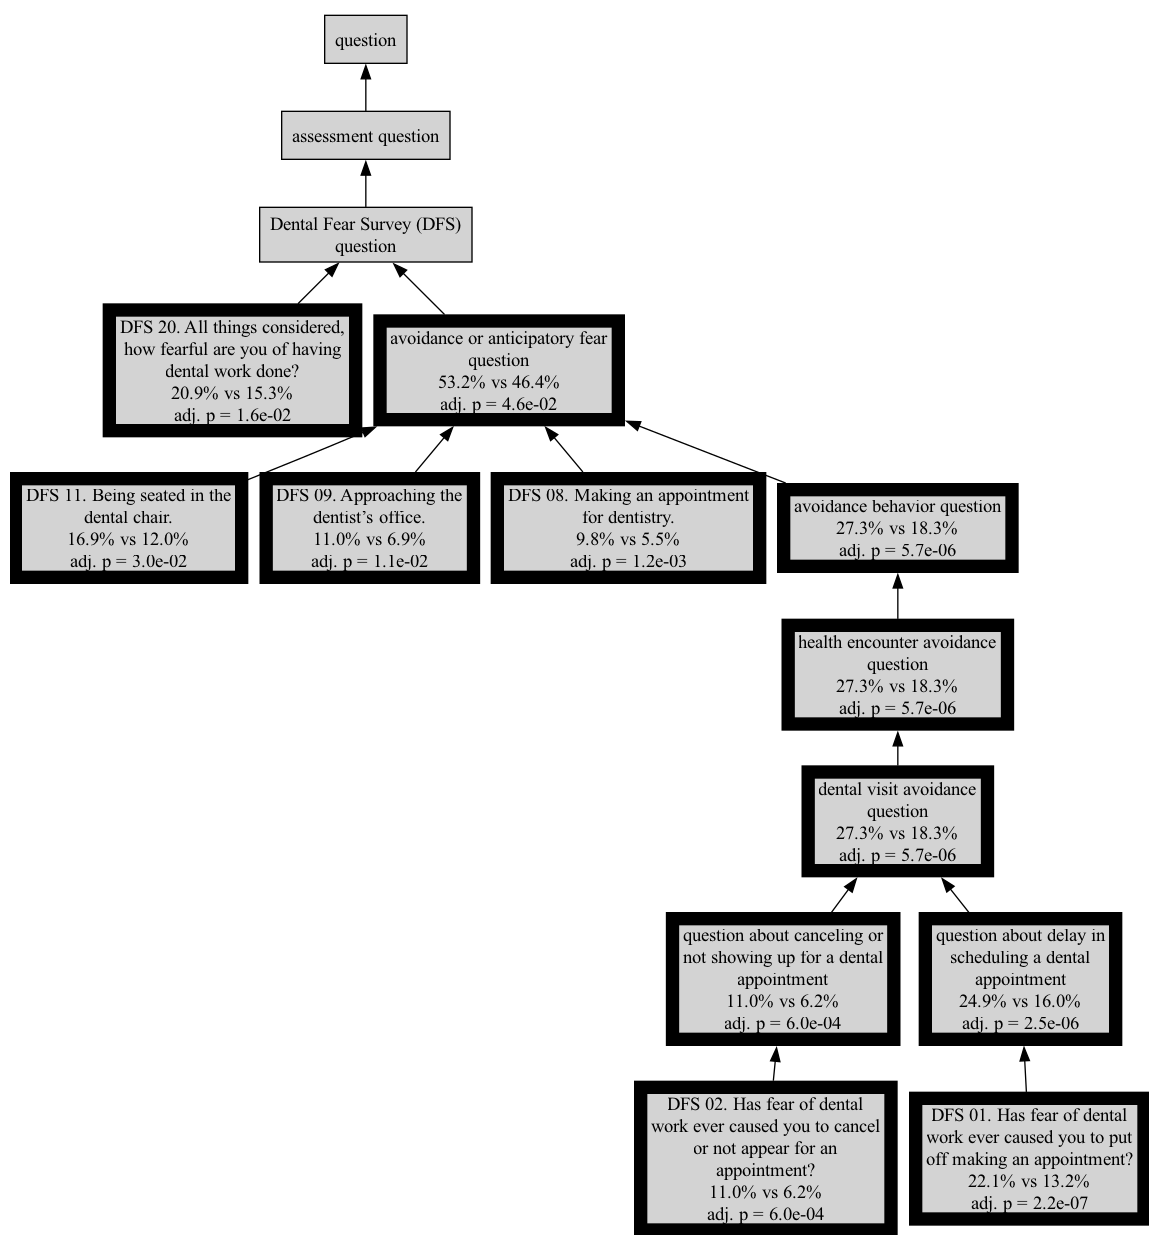

In [16]:
show_image(ENRICH_DIR / "enrichment-dfs-last-visit-5plus-years.png")